<a href="https://colab.research.google.com/github/monishreddy48/data-science-fundamentals/blob/main/Data_Science_Fundamentals_Assessment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== 1. DATASET OVERVIEW ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB
None

Missing Values Audit:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64


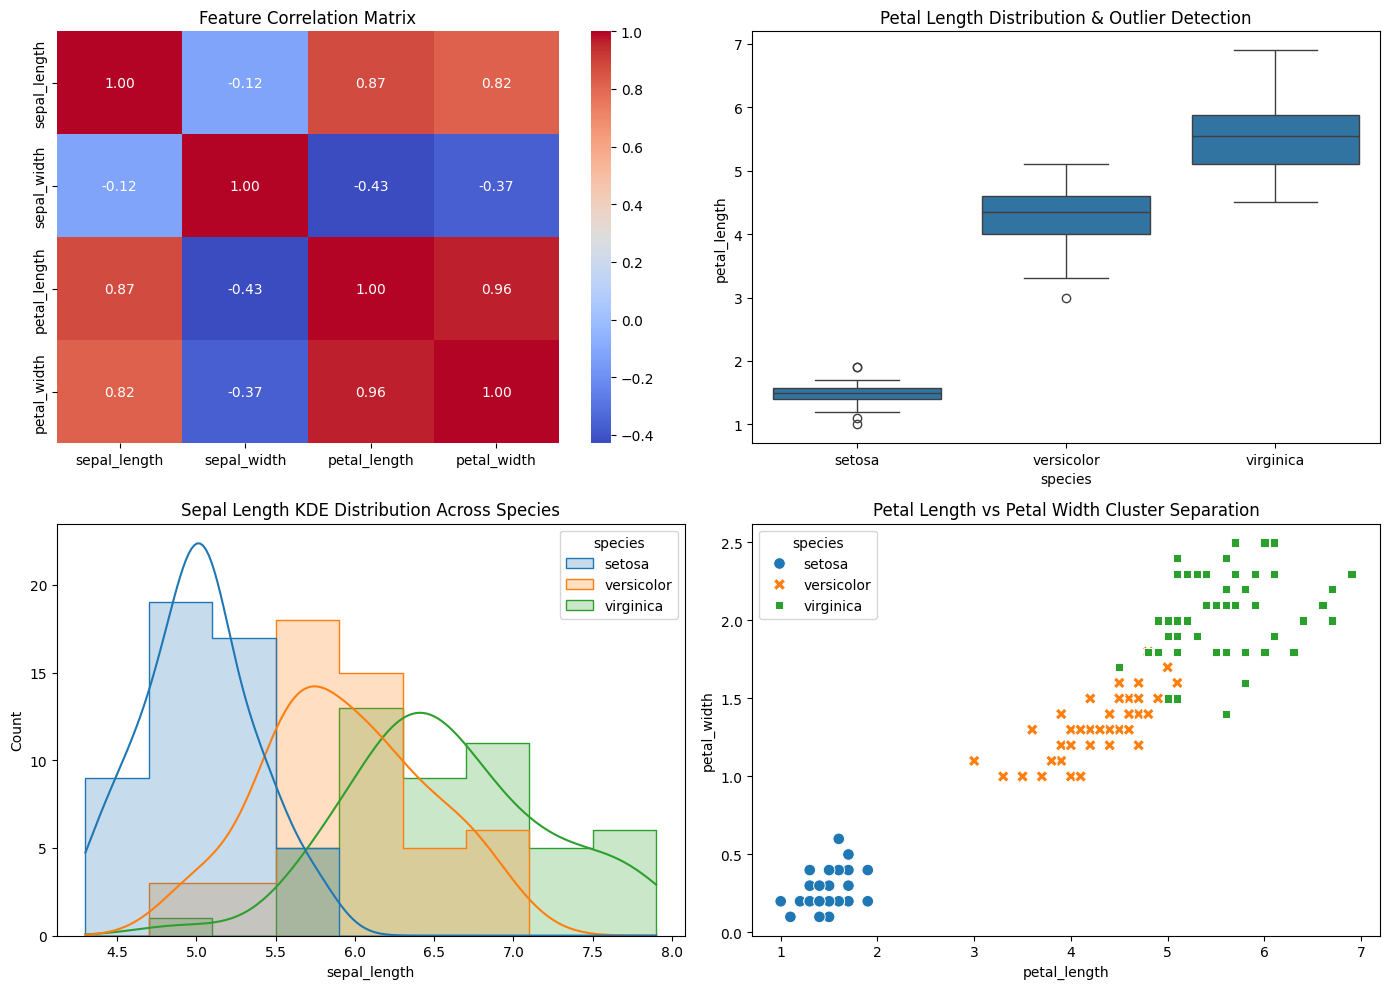


=== 2. STATISTICAL HYPOTHESIS TESTING (Independent Two-Sample T-Test) ===
Comparison: Versicolor vs. Virginica (Sepal Length)
T-statistic: -5.6292
P-value: 1.7249e-07
Result: Reject Null Hypothesis (H0). Statistically significant difference confirmed (p < 0.05).

=== 3. MACHINE LEARNING MODEL EVALUATION ===
Random Forest Classifier Accuracy: 90.00%

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



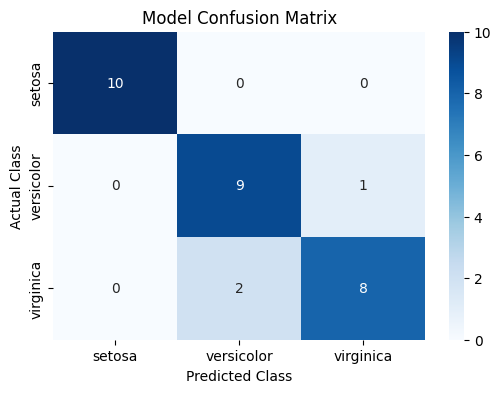


=== 4. DEPLOYMENT PIPELINE ARTIFACTS ===
Serialized 'iris_random_forest_model.pkl' and 'scaler_preprocessor.pkl'.
Ready for REST API integration (FastAPI/Flask) or cloud microservices.


In [2]:
# ==============================================================================
# Comprehensive Data Science Fundamentals Assessment & ML Lifecycle
# ==============================================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# ------------------------------------------------------------------------------
# 1. Dataset Ingestion & Validation
# ------------------------------------------------------------------------------
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"
df = pd.read_csv(url)

print("=== 1. DATASET OVERVIEW ===")
print(df.info())
print("\nMissing Values Audit:")
print(df.isnull().sum())

# ------------------------------------------------------------------------------
# 2. Detailed Exploratory Data Analysis (EDA)
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Subplot A: Correlation Heatmap
corr = df.drop(columns=["species"]).corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", ax=axes[0, 0])
axes[0, 0].set_title("Feature Correlation Matrix")

# Subplot B: Boxplot for Outlier Detection (Petal Length by Species)
sns.boxplot(x="species", y="petal_length", data=df, ax=axes[0, 1])
axes[0, 1].set_title("Petal Length Distribution & Outlier Detection")

# Subplot C: Distribution & KDE Plot (Sepal Length)
sns.histplot(
    data=df,
    x="sepal_length",
    hue="species",
    kde=True,
    element="step",
    ax=axes[1, 0],
)
axes[1, 0].set_title("Sepal Length KDE Distribution Across Species")

# Subplot D: Petal Dimensions Scatter Analysis
sns.scatterplot(
    data=df,
    x="petal_length",
    y="petal_width",
    hue="species",
    style="species",
    s=70,
    ax=axes[1, 1],
)
axes[1, 1].set_title("Petal Length vs Petal Width Cluster Separation")

plt.tight_layout()
plt.savefig("detailed_eda_visualizations.png")
plt.show()

# ------------------------------------------------------------------------------
# 3. Formal Statistical Hypothesis Testing
# ------------------------------------------------------------------------------
# Hypothesis: Versicolor and Virginica have significantly different sepal lengths.
# H0: Mean sepal length of Versicolor == Mean sepal length of Virginica
# H1: Mean sepal length of Versicolor != Mean sepal length of Virginica

versicolor_sepal = df[df["species"] == "versicolor"]["sepal_length"]
virginica_sepal = df[df["species"] == "virginica"]["sepal_length"]

t_stat, p_val = stats.ttest_ind(versicolor_sepal, virginica_sepal)

print("\n=== 2. STATISTICAL HYPOTHESIS TESTING (Independent Two-Sample T-Test) ===")
print(f"Comparison: Versicolor vs. Virginica (Sepal Length)")
print(f"T-statistic: {t_stat:.4f}")
print(f"P-value: {p_val:.4e}")
if p_val < 0.05:
  print(
      "Result: Reject Null Hypothesis (H0). Statistically significant"
      " difference confirmed (p < 0.05)."
  )
else:
  print(
      "Result: Fail to reject Null Hypothesis (H0). No statistically"
      " significant difference."
  )

# ------------------------------------------------------------------------------
# 4. Feature Engineering & Dataset Splitting
# ------------------------------------------------------------------------------
X = df.drop(columns=["species"])
y = df["species"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ------------------------------------------------------------------------------
# 5. Machine Learning Workflow: Model Training & Evaluation
# ------------------------------------------------------------------------------
clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(X_train_scaled, y_train)

y_pred = clf.predict(X_test_scaled)
acc = accuracy_score(y_test, y_pred)

print("\n=== 3. MACHINE LEARNING MODEL EVALUATION ===")
print(f"Random Forest Classifier Accuracy: {acc * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))

# Confusion Matrix Visualization
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=clf.classes_,
    yticklabels=clf.classes_,
)
plt.title("Model Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.savefig("confusion_matrix.png")
plt.show()

# ------------------------------------------------------------------------------
# 6. Production Deployment Architecture (Model Serialization Simulation)
# ------------------------------------------------------------------------------
import joblib

joblib.dump(clf, "iris_random_forest_model.pkl")
joblib.dump(scaler, "scaler_preprocessor.pkl")
print(
    "\n=== 4. DEPLOYMENT PIPELINE ARTIFACTS ==="
)
print("Serialized 'iris_random_forest_model.pkl' and 'scaler_preprocessor.pkl'.")
print("Ready for REST API integration (FastAPI/Flask) or cloud microservices.")